# Introduction to Deep Learning, Assignment 2, Task 2

### Function definitions for creating the datasets

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
import numpy as np
import random
from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import Dense, LSTM, Flatten, TimeDistributed
from tensorflow.keras.layers import RepeatVector, Conv2D, Reshape, ConvLSTM2D, Conv2DTranspose, Dropout, BatchNormalization, MaxPooling2D
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(21)
np.random.seed(21)
random.seed(21)
tf.config.experimental.enable_op_determinism()

# defining consistent color palette across the notebook
set2_colors = plt.cm.Set2.colors
viridis = plt.cm.viridis

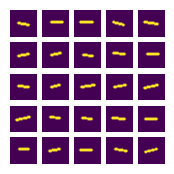

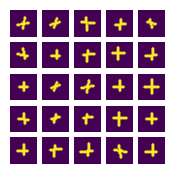

In [2]:
# Create plus/minus operand signs
def generate_images(number_of_images=50, sign='-'):
    blank_images = np.zeros([number_of_images, 28, 28])  # Dimensionality matches the size of MNIST images (28x28)
    x = np.random.randint(12, 16, (number_of_images, 2)) # Randomized x coordinates
    y1 = np.random.randint(6, 10, number_of_images)       # Randomized y coordinates
    y2 = np.random.randint(18, 22, number_of_images)     # -||-

    for i in range(number_of_images): # Generate n different images
        cv2.line(blank_images[i], (y1[i], x[i,0]), (y2[i], x[i, 1]), (255,0,0), 2, cv2.LINE_AA)     # Draw lines with randomized coordinates
        if sign == '+':
            cv2.line(blank_images[i], (x[i,0], y1[i]), (x[i, 1], y2[i]), (255,0,0), 2, cv2.LINE_AA) # Draw lines with randomized coordinates

    return blank_images

def show_generated(images, n=5):
    plt.figure(figsize=(2, 2))
    for i in range(n**2):
        plt.subplot(n, n, i+1)
        plt.axis('off')
        plt.imshow(images[i])
    plt.show()

show_generated(generate_images())
show_generated(generate_images(sign='+'))

In [3]:
def create_data(highest_integer, num_addends=2, operands=['+', '-']):
    """
    Creates the following data for all pairs of integers up to [1:highest integer][+/-][1:highest_integer]:

    @return:
    X_text: '51+21' -> text query of an arithmetic operation (5)
    X_img : Stack of MNIST images corresponding to the query (5 x 28 x 28) -> sequence of 5 images of size 28x28
    y_text: '72' -> answer of the arithmetic text query
    y_img :  Stack of MNIST images corresponding to the answer (3 x 28 x 28)

    Images for digits are picked randomly from the whole MNIST dataset.
    """

    num_indices = [np.where(MNIST_labels==x) for x in range(10)]
    num_data = [MNIST_data[inds] for inds in num_indices]
    image_mapping = dict(zip(unique_characters[:10], num_data))
    image_mapping['-'] = generate_images()
    image_mapping['+'] = generate_images(sign='+')
    image_mapping['*'] = generate_images(sign='*')
    image_mapping[' '] = np.zeros([1, 28, 28])

    X_text, X_img, y_text, y_img = [], [], [], []

    for i in range(highest_integer + 1):      # First addend
        for j in range(highest_integer + 1):  # Second addend
            for sign in operands: # Create all possible combinations of operands
                query_string = to_padded_chars(str(i) + sign + str(j), max_len=max_query_length, pad_right=True)
                query_image = []
                for n, char in enumerate(query_string):
                    image_set = image_mapping[char]
                    index = np.random.randint(0, len(image_set), 1)
                    query_image.append(image_set[index].squeeze())

                result = eval(query_string)
                result_string = to_padded_chars(result, max_len=max_answer_length, pad_right=True)
                result_image = []
                for n, char in enumerate(result_string):
                    image_set = image_mapping[char]
                    index = np.random.randint(0, len(image_set), 1)
                    result_image.append(image_set[index].squeeze())

                X_text.append(query_string)
                X_img.append(np.stack(query_image))
                y_text.append(result_string)
                y_img.append(np.stack(result_image))

    return np.stack(X_text), np.stack(X_img)/255., np.stack(y_text), np.stack(y_img)/255.

def to_padded_chars(integer, max_len=3, pad_right=False):
    """
    Returns a string of len()=max_len, containing the integer padded with ' ' on either right or left side
    """
    length = len(str(integer))
    padding = (max_len - length) * ' '
    if pad_right:
        return str(integer) + padding
    else:
        return padding + str(integer)


### Creating our data

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(20000,) (20000, 5, 28, 28) (20000,) (20000, 3, 28, 28)
Query #2890

X_text: "14+45" = y_text: "59 "
(20000,) (20000, 5, 28, 28) (20000,) (20000, 3, 28, 28)
Query #2890

X_text: "14+45" = y_text: "59 "


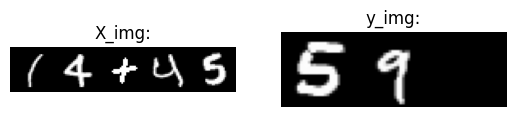

Query #3022

X_text: "15+11" = y_text: "26 "


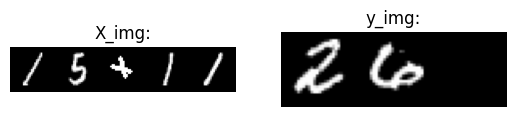

Query #4363

X_text: "21-81" = y_text: "-60"


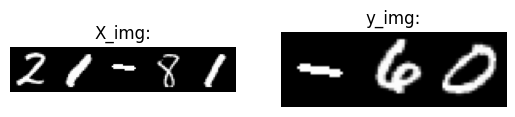

Query #8355

X_text: "41-77" = y_text: "-36"


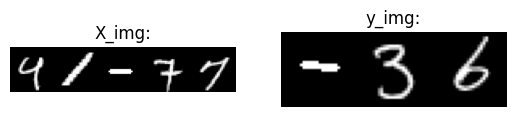

Query #7652

X_text: "38+26" = y_text: "64 "


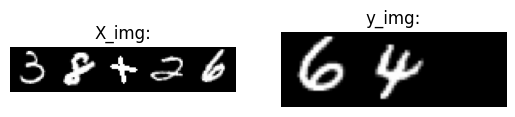

Query #1272

X_text: "6+36 " = y_text: "42 "


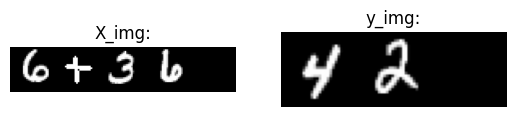

Query #3373

X_text: "16-86" = y_text: "-70"


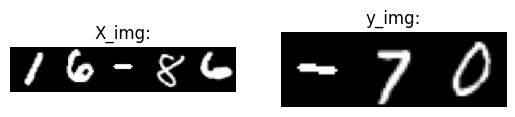

Query #4315

X_text: "21-57" = y_text: "-36"


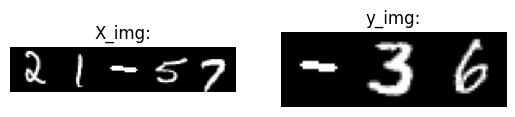

Query #7373

X_text: "36-86" = y_text: "-50"


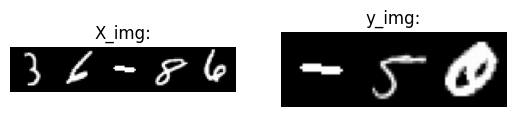

Query #722

X_text: "3+61 " = y_text: "64 "


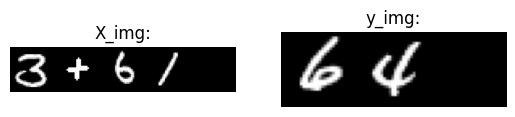

In [4]:
# Illustrate the generated query/answer pairs

unique_characters = '0123456789+- '       # All unique characters that are used in the queries (13 in total: digits 0-9, 2 operands [+, -], and a space character ' '.)
highest_integer = 99                      # Highest value of integers contained in the queries

max_int_length = len(str(highest_integer))# Maximum number of characters in an integer
max_query_length = max_int_length * 2 + 1 # Maximum length of the query string (consists of two integers and an operand [e.g. '22+10'])
max_answer_length = 3    # Maximum length of the answer string (the longest resulting query string is ' 1-99'='-98')

# Create the data (might take around a minute)
(MNIST_data, MNIST_labels), _ = tf.keras.datasets.mnist.load_data()
X_text, X_img, y_text, y_img = create_data(highest_integer)
print(X_text.shape, X_img.shape, y_text.shape, y_img.shape)


## Display the samples that were created
def display_sample(n):
    labels = ['X_img:', 'y_img:']
    for i, data in enumerate([X_img, y_img]):
        plt.subplot(1,2,i+1)
        # plt.set_figheight(15)
        plt.axis('off')
        plt.title(labels[i])
        plt.imshow(np.hstack(data[n]), cmap='gray')
    print('='*50, f'\nQuery #{n}\n\nX_text: "{X_text[n]}" = y_text: "{y_text[n]}"')
    plt.show()

for _ in range(10):
    display_sample(np.random.randint(0, 10000, 1)[0])

### Helper functions

In [5]:
# One-hot encoding/decoding the text queries/answers so that they can be processed using RNNs
# You should use these functions to convert your strings and read out the output of your networks

def encode_labels(labels, max_len=3):
  n = len(labels)
  length = len(labels[0])
  char_map = dict(zip(unique_characters, range(len(unique_characters))))
  one_hot = np.zeros([n, length, len(unique_characters)])
  for i, label in enumerate(labels):
      m = np.zeros([length, len(unique_characters)])
      for j, char in enumerate(label):
          m[j, char_map[char]] = 1
      one_hot[i] = m

  return one_hot


def decode_labels(labels):
    pred = np.argmax(labels, axis=2)
    predicted = [''.join([unique_characters[i] for i in j]) for j in pred]

    return predicted

X_text_onehot = encode_labels(X_text)
y_text_onehot = encode_labels(y_text)

print(X_text_onehot.shape, y_text_onehot.shape)

(20000, 5, 13) (20000, 3, 13)


--- 
### I. Text-to-text RNN model

In [6]:
def build_text2text_model():

    # We start by initializing a sequential model
    text2text = tf.keras.Sequential()

    # "Encode" the input sequence using an RNN, producing an output of size 256.
    # In this case the size of our input vectors is [5, 13] as we have queries of length 5 and 13 unique characters. Each of these 5 elements in the query will be fed to the network one by one,
    # as shown in the image above (except with 5 elements).
    # Hint: In other applications, where your input sequences have a variable length (e.g. sentences), you would use input_shape=(None, unique_characters).
    text2text.add(LSTM(256, input_shape=(None, len(unique_characters))))

    # As the decoder RNN's input, repeatedly provide with the last output of RNN for each time step. Repeat 3 times as that's the maximum length of the output (e.g. '  1-99' = '-98')
    # when using 2-digit integers in queries. In other words, the RNN will always produce 3 characters as its output.
    text2text.add(RepeatVector(max_answer_length))

    # By setting return_sequences to True, return not only the last output but all the outputs so far in the form of (num_samples, timesteps, output_dim). This is necessary as TimeDistributed in the below expects
    # the first dimension to be the timesteps.
    text2text.add(LSTM(256, return_sequences=True))

    # Apply a dense layer to the every temporal slice of an input. For each of step of the output sequence, decide which character should be chosen.
    text2text.add(TimeDistributed(Dense(len(unique_characters), activation='softmax')))

    # Next we compile the model using categorical crossentropy as our loss function.
    text2text.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    text2text.summary()

    return text2text

##### Defining functions to split the data consistently throughout different models, training and evaluating the models, and analyzing errors

In [7]:
# splitting data into train, validation, and test sets
def split_data_with_val(X, y, train_size=0.75, val_size=0.2, random_state=21):
    indices = np.arange(len(X))
    train_idx, test_idx = train_test_split(
        indices, train_size=train_size, random_state=random_state
    )
    X_train_full, X_test = X[train_idx], X[test_idx]
    y_train_full, y_test = y[train_idx], y[test_idx]
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=val_size, random_state=random_state
    )
    return X_train, X_val, X_test, y_train, y_val, y_test, train_idx, test_idx

# training and evaluating model
def train_evaluate_model(model, X_train, y_train, X_val, y_val, X_test, y_test,
                         epochs=100, batch_size=128, patience=10, verbose=0):
    early_stopping = EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                        validation_data=(X_val, y_val), callbacks=[early_stopping], verbose=verbose)
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    return history, acc

# analyzing errors made by the model
def analyze_errors(model, X_data, y_true_onehot, queries_raw):
    print("Error Analysis:")

    preds = model.predict(X_data, verbose=0)
    decoded_preds = decode_labels(preds)
    decoded_true = decode_labels(y_true_onehot)
    queries = queries_raw

    error_counts = {
        "Sign Error": 0,
        "Overflow Error": 0,
        "Carry/Borrow Error": 0,
        "Single Digit Error": 0,
        "Magnitude Error": 0,
        "Format Error": 0
    }

    mistake_indices = []
    detailed_errors = []  

    for i in range(len(decoded_preds)):
        pred = decoded_preds[i].strip()
        true = decoded_true[i].strip()

        if pred != true:
            mistake_indices.append(i)
            try:
                p_val = int(pred)
                t_val = int(true)
                diff = p_val - t_val  
                abs_diff = abs(diff)

                pred_digits = len(pred.lstrip("-"))
                true_digits = len(true.lstrip("-"))
                if pred_digits != true_digits:
                    error_counts["Overflow Error"] += 1
                    detailed_errors.append((queries[i], true, pred, "Overflow Error", diff))
                elif (p_val < 0 and t_val > 0) or (p_val > 0 and t_val < 0):
                    error_counts["Sign Error"] += 1
                    detailed_errors.append((queries[i], true, pred, "Sign Error", diff))
                elif abs_diff > 0 and abs_diff % 10 == 0:
                    error_counts["Carry/Borrow Error"] += 1
                    detailed_errors.append((queries[i], true, pred, "Carry/Borrow Error", diff))
                elif 1 <= abs_diff <= 9:
                    error_counts["Single Digit Error"] += 1
                    detailed_errors.append((queries[i], true, pred, "Single Digit Error", diff))
                else:
                    error_counts["Magnitude Error"] += 1
                    detailed_errors.append((queries[i], true, pred, "Magnitude Error", diff))
            except ValueError:
                error_counts["Format Error"] += 1
                detailed_errors.append((queries[i], true, pred, "Format Error", None))

    total = len(decoded_preds)
    err_count = len(mistake_indices)
    accuracy = 1 - err_count / total
    print(f"Accuracy: {accuracy:.2%}")
    print(f"Total Errors: {err_count} / {total}")
    
    print("Example of each error type:")
    examples_found = set()
    for query, true, pred, category, diff in detailed_errors:
        error_type_key = category
        
        if error_type_key and error_type_key not in examples_found:
            examples_found.add(error_type_key)
            if diff is not None:
                print(f"{error_type_key}: '{query.strip()}' -> True: {true}, Predicted: {pred} (diff: {diff:+d})")
            else:
                print(f"{error_type_key}: '{query.strip()}' -> True: {true}, Predicted: {pred}")
    print()

    return error_counts, accuracy, detailed_errors

##### Assessing different train/test splits and resulting errors

Training with 75% data:


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 256)            │       276,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 3, 13)          │         3,341 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 805,133 (3.07 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_8 (LSTM)                   │ (None, 256)            │       276,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_4 (RepeatVector)  │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_9 (LSTM)                   │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 3, 13)          │         3,341 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 805,133 (3.07 MB)

 Trainable params: 805,133 (3.07 MB)

 Non-trainable params: 0 (0.00 B)

Test Accuracy: 0.4834
Error Analysis for 5% Training Data:
Error Analysis:
Accuracy: 3.21%
Total Errors: 18390 / 19000
Example of each error type:
Magnitude Error: '39+17' -> True: 56, Predicted: 70 (diff: +14)
Single Digit Error: '40+69' -> True: 109, Predicted: 116 (diff: +7)
Carry/Borrow Error: '38+91' -> True: 129, Predicted: 139 (diff: +10)
Sign Error: '22-9' -> True: 13, Predicted: -10 (diff: -23)
Overflow Error: '3+42' -> True: 45, Predicted: 4 (diff: -41)
Format Error: '43-8' -> True: 35, Predicted: -

Accuracy: 3.21%
Total Errors: 18390 / 19000
Example of each error type:
Magnitude Error: '39+17' -> True: 56, Predicted: 70 (diff: +14)
Single Digit Error: '40+69' -> True: 109, Predicted: 116 (diff: +7)
Carry/Borrow Error: '38+91' -> True: 129, Predicted: 139 (diff: +10)
Sign Error: '22-9' -> True: 13, Predicted: -10 (diff: -23)
Overflow Error: '3+42' -> True: 45, Predicted: 4 (diff: -41)
Format Error: '43-8' -> True: 35, Predicted: -



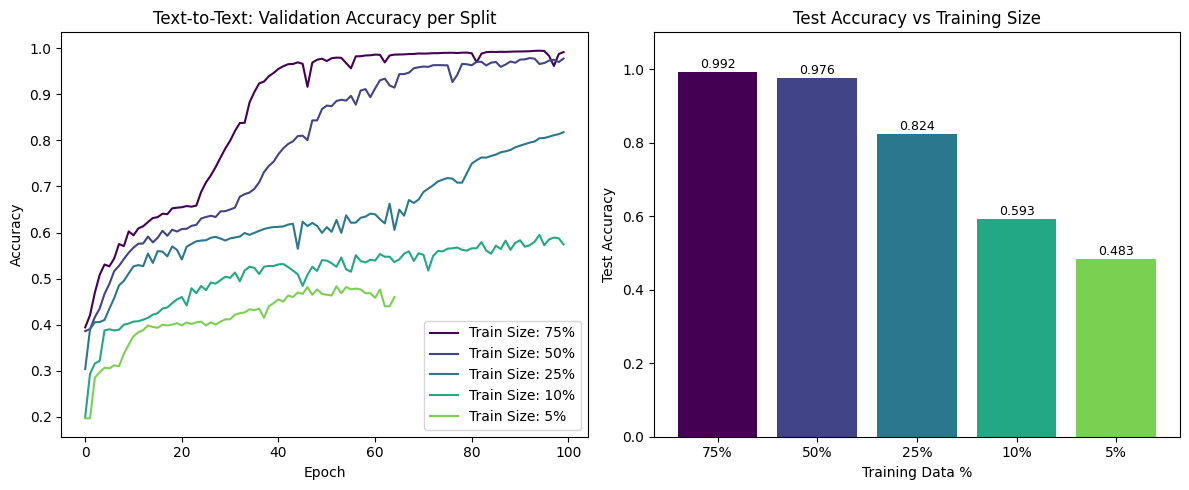

Final Test Accuracy vs Training Size
75% | 0.9924
50% | 0.9759
25% | 0.8236
10% | 0.5926
5% | 0.4834
Accuracy Drops Between Splits:
Split Change | Accuracy Drop
75% -> 50% | 0.0165
50% -> 25% | 0.1523
25% -> 10% | 0.2310
10% -> 5% | 0.1092


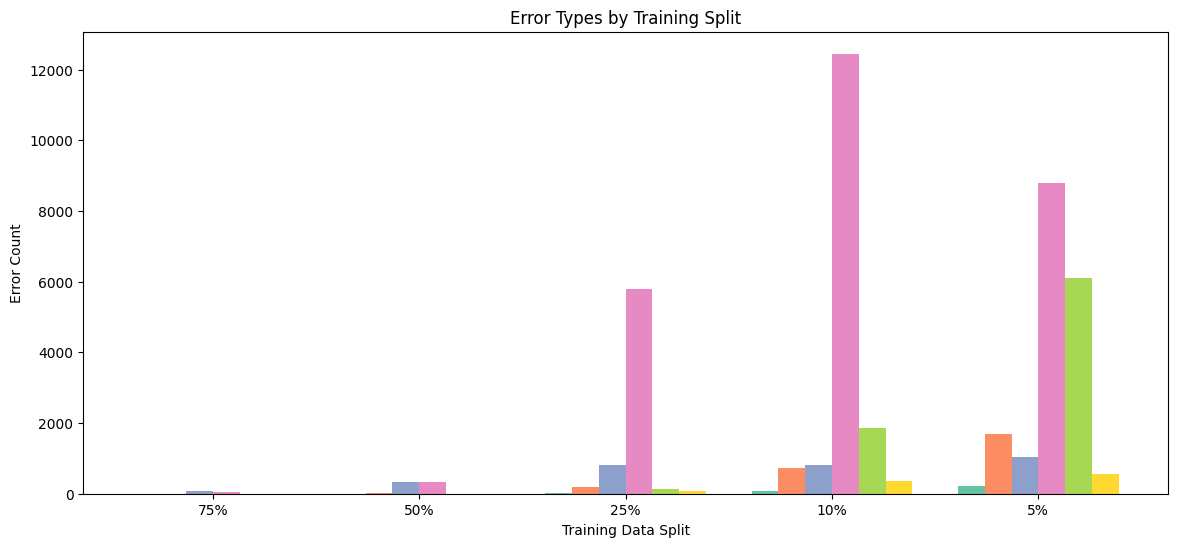

In [8]:
# assessing model performance across different train/test splits
def assess_splits(splits, X_text_raw, y_text_raw):
    history_dict = {}
    accuracy_dict = {}
    error_analysis_dict = {}

    for split in splits:
        print(f"Training with {split*100:.0f}% data:")
        
        # splitting data
        X_train, X_val, X_test, y_train, y_val, y_test, train_idx, test_idx = split_data_with_val(
            X_text_onehot, y_text_onehot, train_size=split
        )
        X_test_raw_str = X_text_raw[test_idx]

        # building and training model
        text2text_model = build_text2text_model()
        history, acc = train_evaluate_model(
            text2text_model, X_train, y_train, X_val, y_val, X_test, y_test
        )

        print(f"Test Accuracy: {acc:.4f}")
        history_dict[split] = history
        accuracy_dict[split] = acc

        # performing error analysis
        print(f"Error Analysis for {split*100:.0f}% Training Data:")
        error_counts, _, detailed_errors = analyze_errors(text2text_model, X_test, y_test, X_test_raw_str)
        error_analysis_dict[split] = error_counts

    return history_dict, accuracy_dict, error_analysis_dict

# defining splits (75%, 50%, 25%, 10%, and 5%)
splits = [0.75, 0.5, 0.25, 0.1, 0.05]

# running assessment
results, accuracies, error_counts_by_split = assess_splits(splits, X_text, y_text)

# plotting final comparison
plt.figure(figsize=(12, 5))

# defining colors to match lines and bars
colors = [viridis(i/len(splits)) for i in range(len(splits))]

plt.subplot(1, 2, 1)
for i, split in enumerate(splits):
    hist = results[split]
    plt.plot(hist.history["val_accuracy"], label=f"Train Size: {int(split * 100)}%", color=colors[i])
plt.title("Text-to-Text: Validation Accuracy per Split")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
split_labels = [f"{int(s*100)}%" for s in splits]
acc_values = [accuracies[s] for s in splits]
plt.bar(split_labels, acc_values, color=colors)
plt.title("Test Accuracy vs Training Size")
plt.ylabel("Test Accuracy")
plt.xlabel("Training Data %")
for i, (label, acc) in enumerate(zip(split_labels, acc_values)):
    plt.text(i, acc + 0.01, f"{acc:.3f}", ha="center", fontsize=9)
plt.ylim(0, 1.1)

plt.tight_layout()
plt.savefig("t2t_results.png")
plt.show()

# summarizing final accuracy vs training size
print("Final Test Accuracy vs Training Size")
final_accs = {split: accuracies[split] for split in results.keys()}
for split, acc in sorted(final_accs.items(), reverse=True):
    print(f"{int(split*100)}% | {acc:.4f}")

print("Accuracy Drops Between Splits:")
print("Split Change | Accuracy Drop")
sorted_splits = sorted(final_accs.items(), reverse=True)
for (current_split, current_acc), (next_split, next_acc) in zip(sorted_splits, sorted_splits[1:]):
    acc_drop = current_acc - next_acc
    print(f"{int(current_split*100)}% -> {int(next_split*100)}% | {acc_drop:.4f}")

# comparing error type distribution across splits
error_types = list(error_counts_by_split[splits[0]].keys())
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(splits))
width = 0.13

for i, error_type in enumerate(error_types):
    counts = [error_counts_by_split[s][error_type] for s in splits]
    ax.bar(x + i*width, counts, width, label=error_type.split()[0], color=set2_colors[i])

ax.set_xlabel("Training Data Split")
ax.set_ylabel("Error Count")
ax.set_title("Error Types by Training Split")
ax.set_xticks(x + width * 2.5)
ax.set_xticklabels([f"{int(s*100)}%" for s in splits])

plt.savefig("t2t_errors.png")

plt.show()

---
### II. Image to text RNN Model

Training Image-to-Text with 75% data


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d (ConvLSTM2D)        │ (None, 5, 28, 28, 32)  │        38,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5, 28, 28, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, 5, 14, 14, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_1 (ConvLSTM2D)      │ (None, 5, 14, 14, 64)  │       221,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 5, 14, 14, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, 5, 7, 7, 64)    │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_2 (ConvLSTM2D)      │ (None, 7, 7, 128)      │       885,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_5 (RepeatVector)  │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_10 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, 3, 13)          │         3,341 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,280,269 (12.51 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d_12 (ConvLSTM2D)     │ (None, 5, 28, 28, 32)  │        38,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 5, 28, 28, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_17             │ (None, 5, 14, 14, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_13 (ConvLSTM2D)     │ (None, 5, 14, 14, 64)  │       221,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 5, 14, 14, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_18             │ (None, 5, 7, 7, 64)    │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_14 (ConvLSTM2D)     │ (None, 7, 7, 128)      │       885,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_9 (RepeatVector)  │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_14 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_19             │ (None, 3, 13)          │         3,341 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,280,269 (12.51 MB)

 Trainable params: 3,279,821 (12.51 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 169ms/step - accuracy: 0.1810 - loss: 2.4623 - val_accuracy: 0.1967 - val_loss: 2.5300
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 169ms/step - accuracy: 0.1810 - loss: 2.4623 - val_accuracy: 0.1967 - val_loss: 2.5300
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.2825 - loss: 2.3260 - val_accuracy: 0.1967 - val_loss: 2.4925
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.2825 - loss: 2.3260 - val_accuracy: 0.1967 - val_loss: 2.4925
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.3049 - loss: 2.2918 - val_accuracy: 0.2967 - val_loss: 2.4579
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.3049 - loss: 2.2918 - val_accuracy: 0.2967 - val_loss: 2.4579
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.3234 - loss: 2.2282 - val_accuracy: 0.2967 - val_loss: 2.4173
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.3234 - loss: 2.2282 - val_accuracy

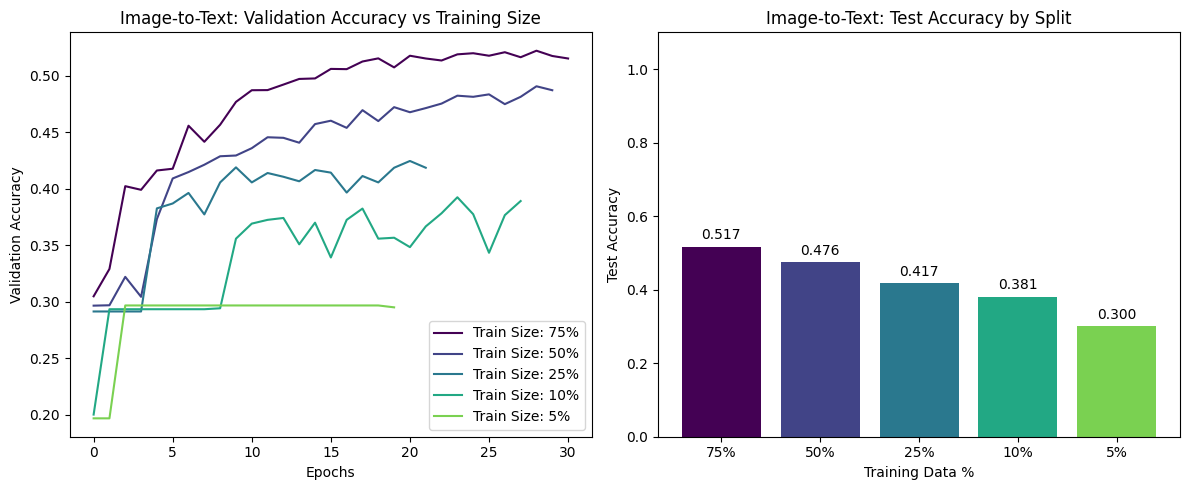

In [9]:
# building image-to-text model using ConvLSTM2D
def build_img2text_model():
    img2text = tf.keras.Sequential()

    # encoding with ConvLSTM2D, using stride (1, 1)
    img2text.add(ConvLSTM2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding="same",
                            return_sequences=True, input_shape=(5, 28, 28, 1), dropout=0.3))
    img2text.add(BatchNormalization())
    img2text.add(TimeDistributed(MaxPooling2D((2, 2)))) 

    # adding second ConvLSTM2D layer
    img2text.add(ConvLSTM2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding="same",
                            return_sequences=True, dropout=0.3))
    img2text.add(BatchNormalization())
    img2text.add(TimeDistributed(MaxPooling2D((2, 2))))

    # adding third ConvLSTM2D layer
    img2text.add(ConvLSTM2D(filters=128, kernel_size=(3, 3), padding="same",
                            return_sequences=False, dropout=0.3))
    img2text.add(BatchNormalization())

    # flattening
    img2text.add(Flatten())
    img2text.add(Dense(256, activation="relu"))
    img2text.add(Dropout(0.5))

    # decoding 
    img2text.add(RepeatVector(max_answer_length))
    img2text.add(LSTM(256, return_sequences=True))
    img2text.add(TimeDistributed(Dense(len(unique_characters), activation="softmax")))

    img2text.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    img2text.summary()

    return img2text

# training and assessing image-to-text model performance across different splits
def analyze_img2text_splits(splits, X_img_data, y_text_data, X_text_raw):
    if X_img_data.ndim == 4:
        X_img_data = np.expand_dims(X_img_data, axis=-1)

    history_dict = {}
    accuracy_dict = {}
    error_analysis_dict = {}
    best_model = None
    best_split = None

    for split in splits:
        print(f"Training Image-to-Text with {split*100:.0f}% data")

        # splitting data
        X_train, X_val, X_test, y_train, y_val, y_test, _, test_idx = split_data_with_val(
            X_img_data, y_text_data, train_size=split
        )
        X_test_text_raw = X_text_raw[test_idx]

        # building and training model
        img2text_model = build_img2text_model()
        history, acc = train_evaluate_model(
            img2text_model, X_train, y_train, X_val, y_val, X_test, y_test,
            batch_size=64, verbose=1
        )

        print(f"Test Accuracy: {acc:.4f}")
        history_dict[split] = history.history["val_accuracy"]
        accuracy_dict[split] = acc

        if best_model is None or acc > accuracy_dict.get(best_split, 0):
            best_model = img2text_model
            best_split = split
            best_test_data = (X_test, y_test, X_test_text_raw)

        error_counts, _, _ = analyze_errors(img2text_model, X_test, y_test, X_test_text_raw)
        error_analysis_dict[split] = error_counts

    return history_dict, accuracy_dict, error_analysis_dict, best_model, best_test_data

# defining splits
img_splits = [0.75, 0.5, 0.25, 0.1, 0.05]

# running analysis
img2text_results, img2text_accuracies, img2text_error_counts, best_img2text_model, best_test = analyze_img2text_splits(
    img_splits, X_img, y_text_onehot, X_text
)

# visualizing results
plt.figure(figsize=(12, 5))

# defining colors to match lines and bars
colors = [viridis(i/len(img_splits)) for i in range(len(img_splits))]

plt.subplot(1, 2, 1)
for i, (split, val_accs) in enumerate(img2text_results.items()):
    plt.plot(val_accs, label=f"Train Size: {split*100:.0f}%", color=colors[i])
plt.title("Image-to-Text: Validation Accuracy vs Training Size")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
split_labels = [f"{int(s*100)}%" for s in img_splits]
acc_values = [img2text_accuracies[s] for s in img_splits]
plt.bar(split_labels, acc_values, color=colors)
plt.title("Image-to-Text: Test Accuracy by Split")
plt.ylabel("Test Accuracy")
plt.xlabel("Training Data %")
for i, acc in enumerate(acc_values):
    plt.text(i, acc + 0.02, f"{acc:.3f}", ha="center")
plt.ylim(0, 1.1)

plt.tight_layout()
plt.savefig("i2t_results.png")
plt.show()

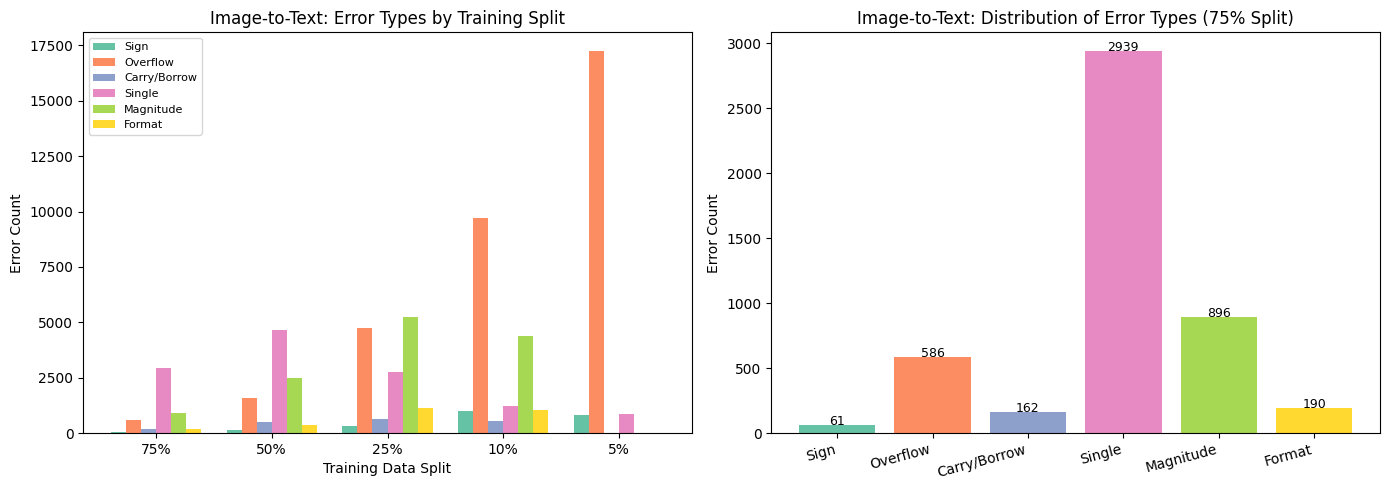

Image-to-Text: Example of each error type:
Error Analysis:
Accuracy: 3.32%
Total Errors: 4834 / 5000
Example of each error type:
Single Digit Error: '40+69' -> True: 109, Predicted: 110 (diff: +1)
Carry/Borrow Error: '12+16' -> True: 28, Predicted: 38 (diff: +10)
Format Error: '50-56' -> True: -6, Predicted: -
Magnitude Error: '41+23' -> True: 64, Predicted: 10 (diff: -54)
Overflow Error: '14-8' -> True: 6, Predicted: 10 (diff: +4)
Sign Error: '19-18' -> True: 1, Predicted: -1 (diff: -2)

Single Digit Error: '40+69' -> True: 109, Predicted: 110 (diff: +1)
Carry/Borrow Error: '12+16' -> True: 28, Predicted: 38 (diff: +10)
Format Error: '50-56' -> True: -6, Predicted: -
Magnitude Error: '41+23' -> True: 64, Predicted: 10 (diff: -54)
Overflow Error: '14-8' -> True: 6, Predicted: 10 (diff: +4)
Sign Error: '19-18' -> True: 1, Predicted: -1 (diff: -2)
Accuracy: 3.32%
Total Errors: 4834 / 5000
Example of each error type:
Single Digit Error: '40+69' -> True: 109, Predicted: 110 (diff: +1)
Carr

In [10]:
# getting error types from the image-to-text analysis
error_types = list(img2text_error_counts[img_splits[0]].keys())

# plotting error distribution for image-to-text across all splits
plt.figure(figsize=(14, 5))

# plotting error type distribution across splits
plt.subplot(1, 2, 1)
x = np.arange(len(img_splits))
width = 0.13

for i, error_type in enumerate(error_types):
    counts = [img2text_error_counts[s][error_type] for s in img_splits]
    plt.bar(x + i*width, counts, width, label=error_type.split()[0], color=set2_colors[i % len(set2_colors)])

plt.xlabel("Training Data Split")
plt.ylabel("Error Count")
plt.title("Image-to-Text: Error Types by Training Split")
plt.xticks(x + width * 2.5, [f"{int(s*100)}%" for s in img_splits])
plt.legend(loc="upper left", fontsize=8)

# plotting standalone error distribution for best split (75%)
plt.subplot(1, 2, 2)
best_split = 0.75
error_counts_75 = img2text_error_counts[best_split]
error_labels = list(error_counts_75.keys())
error_values = list(error_counts_75.values())

bars = plt.bar(range(len(error_labels)), error_values, color=[set2_colors[i % len(set2_colors)] for i in range(len(error_labels))])
plt.xticks(range(len(error_labels)), [label.split()[0] for label in error_labels], rotation=15, ha="right")
plt.ylabel("Error Count")
plt.title(f"Image-to-Text: Distribution of Error Types ({int(best_split*100)}% Split)")

for bar, val in zip(bars, error_values):
    if val > 0:
        plt.text(bar.get_x() + bar.get_width() / 2, val + 1, str(val), ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("i2t_errors.png")
plt.show()

# printing examples for each error type
print("Image-to-Text: Example of each error type:")
X_test_img, y_test_img_text, X_test_img_raw = best_test
_, _, img_detailed_errors_75 = analyze_errors(best_img2text_model, X_test_img, y_test_img_text, X_test_img_raw)

examples_found = set()
for query, true, pred, category, diff in img_detailed_errors_75:
    error_type_key = None
    if category == "Overflow Error":
        error_type_key = "Overflow Error"
    elif category == "Sign Error":
        error_type_key = "Sign Error"
    elif category == "Carry/Borrow Error":
        error_type_key = "Carry/Borrow Error"
    elif category == "Single Digit Error":
        error_type_key = "Single Digit Error"
    elif category == "Magnitude Error":
        error_type_key = "Magnitude Error"
    elif category == "Format Error":
        error_type_key = "Format Error"
    
    if error_type_key and error_type_key not in examples_found:
        examples_found.add(error_type_key)
        if diff is not None:
            print(f"{error_type_key}: '{query.strip()}' -> True: {true}, Predicted: {pred} (diff: {diff:+d})")
        else:
            print(f"{error_type_key}: '{query.strip()}' -> True: {true}, Predicted: {pred}")

Split | Text2Text Acc | Img2Text Acc | Difference
75% | 0.9924 | 0.5167 | -0.4757
50% | 0.9759 | 0.4756 | -0.5003
25% | 0.8236 | 0.4170 | -0.4066
10% | 0.5926 | 0.3806 | -0.2120
5% | 0.4834 | 0.3002 | -0.1832


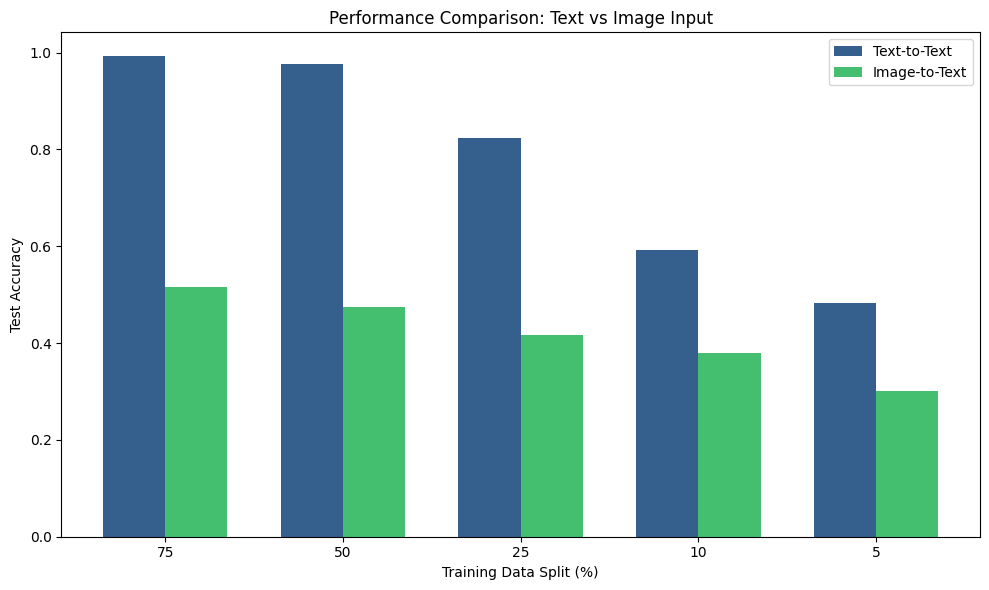

In [11]:
# comparing Text-to-Text and Image-to-Text models
print("Split | Text2Text Acc | Img2Text Acc | Difference")

common_splits = sorted(list(set(accuracies.keys()) & set(img2text_accuracies.keys())), reverse=True)

for split in common_splits:
    t2t_acc = accuracies[split]
    i2t_acc = img2text_accuracies[split]
    diff = i2t_acc - t2t_acc
    print(f"{int(split*100)}% | {t2t_acc:.4f} | {i2t_acc:.4f} | {diff:+.4f}")

# plotting the comparison
plt.figure(figsize=(10, 6))
splits_pct = [int(s*100) for s in common_splits]
x = np.arange(len(common_splits))
width = 0.35

plt.bar(x - width/2, [accuracies[s] for s in common_splits], width, label="Text-to-Text", color=viridis(0.3))
plt.bar(x + width/2, [img2text_accuracies[s] for s in common_splits], width, label="Image-to-Text", color=viridis(0.7))

plt.xlabel("Training Data Split (%)")
plt.ylabel("Test Accuracy")
plt.title("Performance Comparison: Text vs Image Input")
plt.xticks(x, splits_pct)
plt.legend()
plt.tight_layout()
plt.savefig("t2t_vs_i2t_comparison.png")
plt.show()

In [12]:
# exploring alternative architecture using TimeDistributed Conv2D with LSTM
def build_cnn_lstm_model():
    model = tf.keras.Sequential()

    # extracting visual features with TimeDistributed CNN
    model.add(TimeDistributed(Conv2D(32, (3, 3), activation="relu", padding="same"),
                              input_shape=(5, 28, 28, 1)))
    model.add(TimeDistributed(MaxPooling2D((2, 2))))
    model.add(TimeDistributed(Conv2D(64, (3, 3), activation="relu", padding="same")))
    model.add(TimeDistributed(MaxPooling2D((2, 2))))

    # flattening and compressing features
    model.add(TimeDistributed(Flatten()))
    model.add(TimeDistributed(Dense(128, activation="relu")))
    model.add(TimeDistributed(Dropout(0.3)))

    # encoding and decoding sequence
    model.add(LSTM(256, return_sequences=False))
    model.add(RepeatVector(max_answer_length))
    model.add(LSTM(256, return_sequences=True))
    model.add(TimeDistributed(Dense(len(unique_characters), activation="softmax")))

    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    model.summary()

    return model

# building and training the model
cnn_lstm_model = build_cnn_lstm_model()

X_img_exp = np.expand_dims(X_img, axis=-1) if X_img.ndim == 4 else X_img
X_train_cnn, X_val_cnn, X_test_cnn, y_train_cnn, y_val_cnn, y_test_cnn, _, _ = split_data_with_val(
    X_img_exp, y_text_onehot, train_size=0.5
)

history_cnn_lstm, acc = train_evaluate_model(
    cnn_lstm_model, X_train_cnn, y_train_cnn, X_val_cnn, y_val_cnn, X_test_cnn, y_test_cnn,
    batch_size=64, verbose=1
)

print(f"CNN-LSTM Test Accuracy: {acc:.4f}")

# comparing with ConvLSTM2D results
print("Comparing architectures (50% split):")
convlstm_acc = img2text_accuracies.get(0.5, "N/A")
print(f"ConvLSTM2D Accuracy: {convlstm_acc:.4f}" if isinstance(convlstm_acc, float) else f"ConvLSTM2D: {convlstm_acc}")
print(f"CNN-LSTM Accuracy: {acc:.4f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/wrapper.py:27: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_20             │ (None, 5, 28, 28, 32)  │           320 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_21             │ (None, 5, 14, 14, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_22             │ (None, 5, 14, 14, 64)  │        18,496 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_23             │ (None, 5, 7, 7, 64)    │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_24             │ (None, 5, 3136)        │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_25             │ (None, 5, 128)         │       401,536 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_26             │ (None, 5, 128)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_15 (LSTM)                  │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_10 (RepeatVector) │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_16 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_27             │ (None, 3, 13)          │         3,341 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,343,245 (5.12 MB)

 Trainable params: 1,343,245 (5.12 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.2886 - loss: 2.1986 - val_accuracy: 0.3892 - val_loss: 1.9512
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.2886 - loss: 2.1986 - val_accuracy: 0.3892 - val_loss: 1.9512
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.3917 - loss: 1.9024 - val_accuracy: 0.3980 - val_loss: 1.7488
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.3917 - loss: 1.9024 - val_accuracy: 0.3980 - val_loss: 1.7488
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4076 - loss: 1.7132 - val_accuracy: 0.4210 - val_loss: 1.6122
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4076 - loss: 1.7132 - val_accuracy: 0.4210 - val_loss: 1.6122
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4346 - loss: 1.6026 - val_accuracy: 0.4392 - val_loss: 1.5322
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4346 - loss: 1.6026 - 

---
### III. Text to image RNN Model

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_17 (LSTM)                  │ (None, None, 256)      │       276,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_18 (LSTM)                  │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_11 (RepeatVector) │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_19 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_28             │ (None, 3, 3136)        │       805,952 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_29             │ (None, 3, 7, 7, 64)    │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_30             │ (None, 3, 14, 14, 32)  │        18,464 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_31             │ (None, 3, 28, 28, 16)  │         4,624 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_32             │ (None, 3, 28, 28, 1)   │           145 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,156,289 (8.23 MB)

 Trainable params: 2,156,289 (8.23 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.1241 - mae: 0.2527 - val_loss: 0.0548 - val_mae: 0.1191
Epoch 2/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - loss: 0.1241 - mae: 0.2527 - val_loss: 0.0548 - val_mae: 0.1191
Epoch 2/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0546 - mae: 0.1203 - val_loss: 0.0542 - val_mae: 0.1167
Epoch 3/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0546 - mae: 0.1203 - val_loss: 0.0542 - val_mae: 0.1167
Epoch 3/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0543 - mae: 0.1205 - val_loss: 0.0527 - val_mae: 0.1150
Epoch 4/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0543 - mae: 0.1205 - val_loss: 0.0527 - val_mae: 0.1150
Epoch 4/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0521 - mae: 0.1164 - val_loss: 0.0495 - val_mae: 0.1102
Epoch 5/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0521 - mae: 0.1164 - val_loss: 0.0495 - val_mae: 0.1102
Epoch 5/100
188/188 ━━━━━━━━━━━━━━━━━━━━

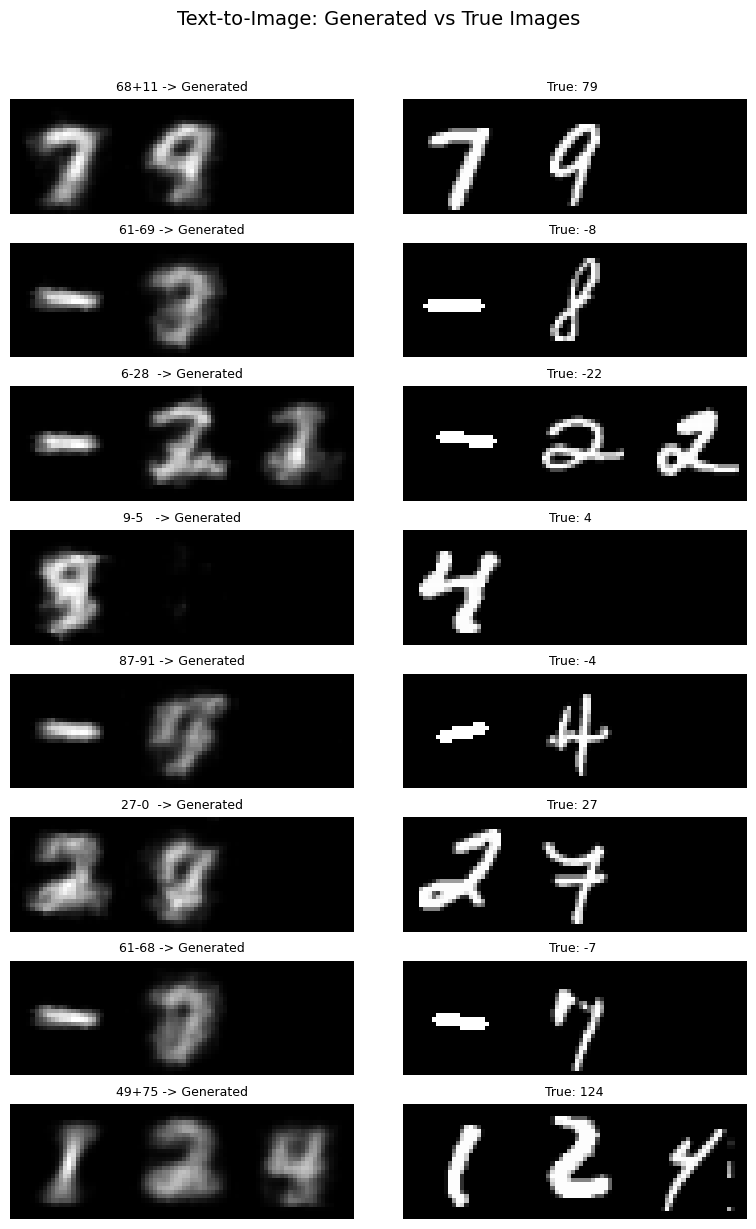

In [13]:
# building text-to-image model
def build_text2img_model():
    text2img_model = tf.keras.Sequential()

    # encoding the text query with stacked LSTMs
    text2img_model.add(LSTM(256, return_sequences=True, input_shape=(None, len(unique_characters))))
    text2img_model.add(LSTM(256, return_sequences=False))

    # repeating for each output image
    text2img_model.add(RepeatVector(max_answer_length))
    text2img_model.add(LSTM(256, return_sequences=True))

    # generating images using deconvolution
    text2img_model.add(TimeDistributed(Dense(7 * 7 * 64, activation="relu")))
    text2img_model.add(TimeDistributed(Reshape((7, 7, 64))))
    text2img_model.add(TimeDistributed(Conv2DTranspose(32, (3, 3), strides=2,
                                                        padding="same", activation="relu")))
    text2img_model.add(TimeDistributed(Conv2DTranspose(16, (3, 3), strides=2,
                                                        padding="same", activation="relu")))
    text2img_model.add(TimeDistributed(Conv2D(1, (3, 3), padding="same", activation="sigmoid")))

    text2img_model.compile(
        loss="mse",
        optimizer=tf.keras.optimizers.Adam(clipnorm=1.0),
        metrics=["mae"]
    )
    text2img_model.summary()

    return text2img_model

# training text-to-image model
text2img_model = build_text2img_model()

# preparing target images
y_img_target = np.expand_dims(y_img, axis=-1)

# splitting the data
X_train_text, X_val_text, X_test_text, y_train_img, y_val_img, y_test_img, train_idx, test_idx = split_data_with_val(
    X_text_onehot, y_img_target, train_size=0.75
)
X_test_text_raw = X_text[test_idx]
y_test_text_raw = y_text[test_idx]

# training the model
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
hist_text2img = text2img_model.fit(
    X_train_text, y_train_img,
    epochs=100,
    batch_size=64,
    validation_data=(X_val_text, y_val_img),
    callbacks=[early_stopping],
    verbose=1
)

# visualizing generated images compared to true images
n_examples = 8
sample_indices = np.random.choice(len(X_test_text), n_examples, replace=False)
sample_preds = text2img_model.predict(X_test_text[sample_indices], verbose=0)

plt.figure(figsize=(8, n_examples * 1.5))
plt.suptitle("Text-to-Image: Generated vs True Images", fontsize=14, y=1.02)

for i, idx in enumerate(sample_indices):
    query = X_test_text_raw[idx]
    answer = y_test_text_raw[idx]

    # generated images
    plt.subplot(n_examples, 2, 2*i + 1)
    gen_row = np.hstack([sample_preds[i, j, :, :, 0] for j in range(3)])
    plt.imshow(gen_row, cmap="gray")
    plt.title(f"{query} -> Generated", fontsize=9)
    plt.axis("off")

    # true images
    plt.subplot(n_examples, 2, 2*i + 2)
    true_row = np.hstack([y_test_img[idx, j, :, :, 0] for j in range(3)])
    plt.imshow(true_row, cmap="gray")
    plt.title(f"True: {answer}", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.savefig("gen_vs_true.png")
plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7231 - loss: 1.0065 - val_accuracy: 0.9760 - val_loss: 0.0790
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7231 - loss: 1.0065 - val_accuracy: 0.9760 - val_loss: 0.0790
Epoch 2/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9598 - loss: 0.1408 - val_accuracy: 0.9801 - val_loss: 0.0651
Epoch 3/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9598 - loss: 0.1408 - val_accuracy: 0.9801 - val_loss: 0.0651
Epoch 3/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9722 - loss: 0.0911 - val_accuracy: 0.9854 - val_loss: 0.0488
Epoch 4/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9722 - loss: 0.0911 - val_accuracy: 0.9854 - val_loss: 0.0488
Epoch 4/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9799 - loss: 0.0683 - val_accuracy: 0.9864 - val_loss: 0.0445
Epoch 5/100
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9799 - loss: 0.0683 - val_accu

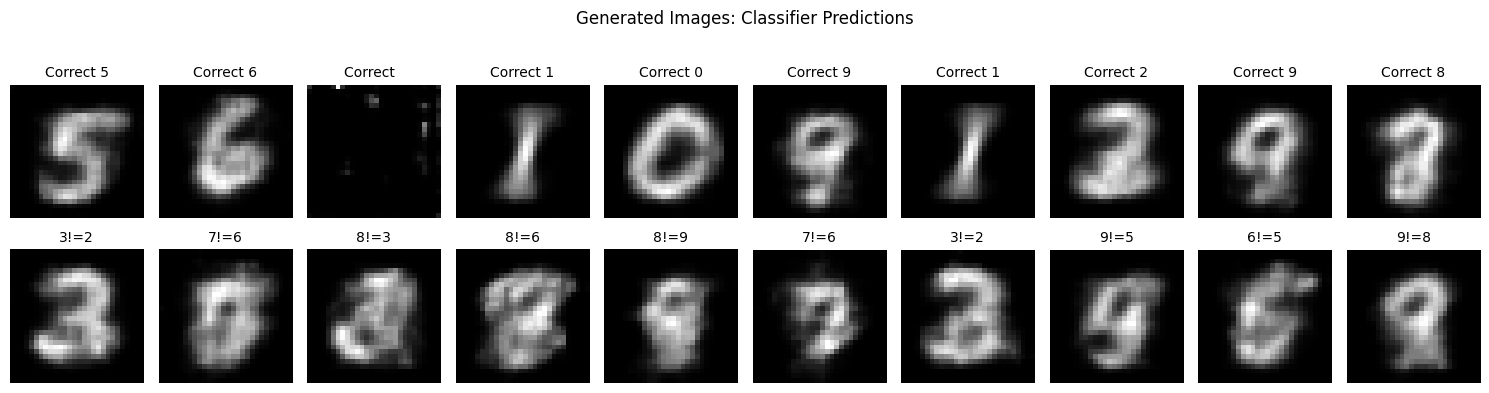

In [14]:
# training a digit classifier to evaluate generated images (optional task)
def build_digit_classifier():
    classifier = tf.keras.Sequential([
        Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation="relu"),
        Flatten(),
        Dense(64, activation="relu"),
        Dropout(0.5),
        Dense(len(unique_characters), activation="softmax")
    ])
    classifier.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return classifier

def prepare_classifier_data(y_images, y_labels):
    X_flat = y_images.reshape(-1, 28, 28, 1)
    y_flat = []
    char_to_idx = {c: i for i, c in enumerate(unique_characters)}
    for label in y_labels:
        for char in label:
            one_hot = np.zeros(len(unique_characters))
            one_hot[char_to_idx[char]] = 1
            y_flat.append(one_hot)
    return X_flat, np.array(y_flat)

# preparing and splitting the data
X_classifier, y_classifier = prepare_classifier_data(y_img, y_text)

X_clf_train, X_clf_val, X_clf_test, y_clf_train, y_clf_val, y_clf_test, _, _ = split_data_with_val(
    X_classifier, y_classifier, train_size=0.8
)

# training the classifier
digit_classifier = build_digit_classifier()
_, clf_acc = train_evaluate_model(
    digit_classifier, X_clf_train, y_clf_train, X_clf_val, y_clf_val, X_clf_test, y_clf_test, verbose=1
)
print(f"Digit Classifier Accuracy on Real Images: {clf_acc:.4f}")

# evaluating the classifier on generated images
gen_images = text2img_model.predict(X_test_text, verbose=0)
gen_images_flat = gen_images.reshape(-1, 28, 28, 1)

_, y_gen_labels = prepare_classifier_data(y_test_img.squeeze(), y_test_text_raw)
gen_preds = digit_classifier.predict(gen_images_flat, verbose=0)
gen_pred_classes = np.argmax(gen_preds, axis=1)
true_classes = np.argmax(y_gen_labels, axis=1)

gen_accuracy = np.mean(gen_pred_classes == true_classes)
print(f"Digit Classifier Accuracy on Generated Images: {gen_accuracy:.4f}")
print(f"Quality Gap: {clf_acc - gen_accuracy:.4f}")

# visualizing correct and incorrect classifications
correct_mask = gen_pred_classes == true_classes
incorrect_indices = np.where(~correct_mask)[0][:10]
correct_indices = np.where(correct_mask)[0][:10]

plt.figure(figsize=(15, 4))
plt.suptitle("Generated Images: Classifier Predictions", y=1.02)

for i, idx in enumerate(correct_indices[:10]):
    plt.subplot(2, 10, i + 1)
    plt.imshow(gen_images_flat[idx].squeeze(), cmap="gray")
    pred_char = unique_characters[gen_pred_classes[idx]]
    plt.title(f"Correct {pred_char}", fontsize=10)
    plt.axis("off")
    if i == 0:
        plt.ylabel("Correct", fontsize=12)

for i, idx in enumerate(incorrect_indices[:10]):
    plt.subplot(2, 10, 10 + i + 1)
    plt.imshow(gen_images_flat[idx].squeeze(), cmap="gray")
    pred_char = unique_characters[gen_pred_classes[idx]]
    true_char = unique_characters[true_classes[idx]]
    plt.title(f"{pred_char}!={true_char}", fontsize=10)
    plt.axis("off")
    if i == 0:
        plt.ylabel("Incorrect", fontsize=12)

plt.tight_layout()
plt.savefig("digit_classifier_results.png")
plt.show()

Comparing stacked LSTM configurations
Configuration: 1 Enc, 1 Dec (Baseline)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_20 (LSTM)                  │ (None, 256)            │       276,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_12 (RepeatVector) │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_21 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_33             │ (None, 3, 13)          │         3,341 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 805,133 (3.07 MB)

 Trainable params: 805,133 (3.07 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_28 (LSTM)                  │ (None, None, 128)      │        72,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_29 (LSTM)                  │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_15 (RepeatVector) │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_30 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_31 (LSTM)                  │ (None, 3, 128)         │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_36             │ (None, 3, 13)          │         1,677 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,191,053 (4.54 MB)

 Trainable params: 1,191,053 (4.54 MB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 1,191,053
Test Accuracy: 0.9984
Error Analysis:
Test Accuracy: 0.9984
Error Analysis:
Accuracy: 99.52%
Total Errors: 24 / 5000
Example of each error type:
Single Digit Error: '0-5' -> True: -5, Predicted: -6 (diff: -1)
Overflow Error: '0-9' -> True: -9, Predicted: -98 (diff: -89)

Error breakdown: {'Sign Error': 0, 'Overflow Error': 3, 'Carry/Borrow Error': 0, 'Single Digit Error': 21, 'Magnitude Error': 0, 'Format Error': 0}
Accuracy: 99.52%
Total Errors: 24 / 5000
Example of each error type:
Single Digit Error: '0-5' -> True: -5, Predicted: -6 (diff: -1)
Overflow Error: '0-9' -> True: -9, Predicted: -98 (diff: -89)

Error breakdown: {'Sign Error': 0, 'Overflow Error': 3, 'Carry/Borrow Error': 0, 'Single Digit Error': 21, 'Magnitude Error': 0, 'Format Error': 0}


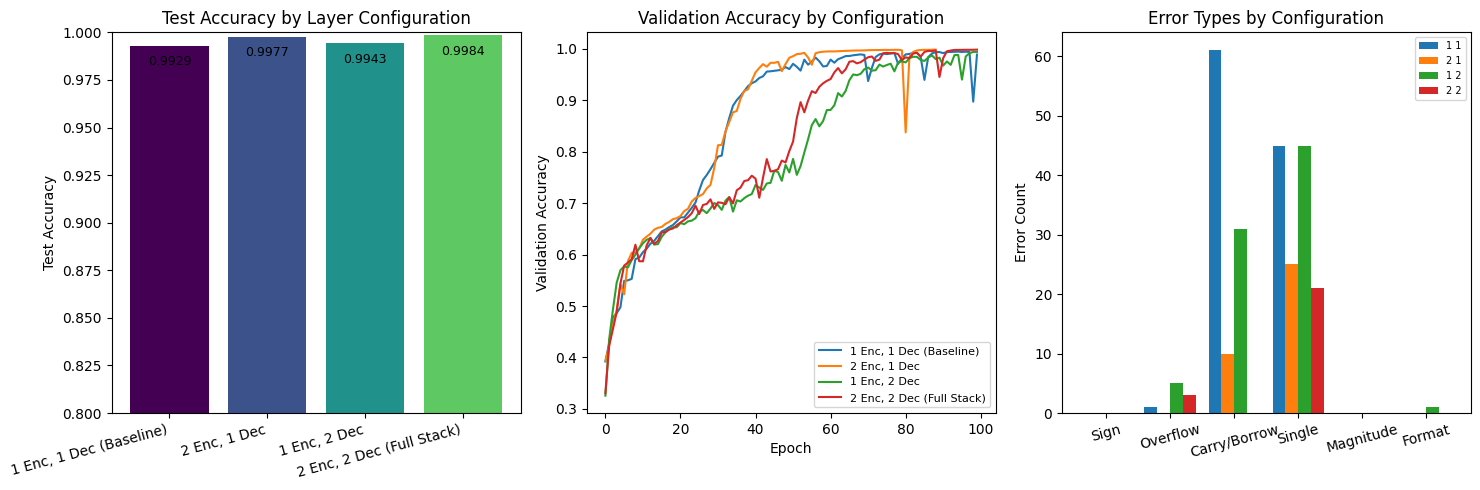

Stacked LSTM Configuration Summary
Configuration | Accuracy | Parameters | Carry Errors
1 Enc, 1 Dec (Baseline) | 0.9929 | 805,133 | 61
2 Enc, 1 Dec | 0.9977 | 995,597 | 10
1 Enc, 2 Dec | 0.9943 | 1,000,589 | 31
2 Enc, 2 Dec (Full Stack) | 0.9984 | 1,191,053 | 0
Carry Error Analysis:
Baseline carry errors: 61
Best configuration (2 Enc, 2 Dec (Full Stack)): 0
Carry error reduction: 100.0%


In [15]:
# building stacked LSTM encoder for text-to-text model
def build_configurable_text2text_model(encoder_layers=1, decoder_layers=1, hidden_size=256):
    """building a text-to-text model with configurable LSTM depth"""
    model = tf.keras.Sequential()

    if encoder_layers == 1:
        model.add(LSTM(hidden_size, input_shape=(None, len(unique_characters))))
    else:
        model.add(LSTM(hidden_size // 2, return_sequences=True, input_shape=(None, len(unique_characters))))
        model.add(LSTM(hidden_size, return_sequences=False))

    model.add(RepeatVector(max_answer_length))

    if decoder_layers == 1:
        model.add(LSTM(hidden_size, return_sequences=True))
    else:
        model.add(LSTM(hidden_size, return_sequences=True))
        model.add(LSTM(hidden_size // 2, return_sequences=True))

    model.add(TimeDistributed(Dense(len(unique_characters), activation="softmax")))
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    model.summary()

    return model

# comparing different layer configurations
print("Comparing stacked LSTM configurations")

configurations = [
    ("1 Enc, 1 Dec (Baseline)", 1, 1),
    ("2 Enc, 1 Dec", 2, 1),
    ("1 Enc, 2 Dec", 1, 2),
    ("2 Enc, 2 Dec (Full Stack)", 2, 2),
]

# splitting the data
X_train, X_val, X_test, y_train, y_val, y_test, _, test_idx = split_data_with_val(
    X_text_onehot, y_text_onehot, train_size=0.75
)
X_test_raw = X_text[test_idx]

stacked_results = {}
stacked_error_counts = {}

for name, enc_layers, dec_layers in configurations:
    print(f"Configuration: {name}")

    model = build_configurable_text2text_model(enc_layers, dec_layers)
    total_params = model.count_params()
    print(f"Total parameters: {total_params:,}")

    history, acc = train_evaluate_model(model, X_train, y_train, X_val, y_val, X_test, y_test)
    print(f"Test Accuracy: {acc:.4f}")

    stacked_results[name] = {
        "accuracy": acc,
        "history": history.history,
        "params": total_params,
        "enc_layers": enc_layers,
        "dec_layers": dec_layers
    }

    error_counts, _, _ = analyze_errors(model, X_test, y_test, X_test_raw)
    stacked_error_counts[name] = error_counts
    print(f"Error breakdown: {error_counts}")

# visualizing the results
plt.figure(figsize=(15, 5))

# visualizing test accuracy
plt.subplot(1, 3, 1)
names = list(stacked_results.keys())
accs = [stacked_results[n]["accuracy"] for n in names]
bars = plt.bar(range(len(names)), accs, color=[viridis(i/len(names)) for i in range(len(names))])
plt.xticks(range(len(names)), names, rotation=15, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy by Layer Configuration")
plt.ylim(0.8, 1.0)
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, acc - 0.005, f"{acc:.4f}",
             ha="center", va="top", fontsize=9)

# visualizing validation accuracy
plt.subplot(1, 3, 2)
for name, data in stacked_results.items():
    plt.plot(data["history"]["val_accuracy"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Configuration")
plt.legend(fontsize=8)

# visualizing error types
plt.subplot(1, 3, 3)
error_types = list(stacked_error_counts[names[0]].keys())
x = np.arange(len(error_types))
width = 0.2
for i, (name, errors) in enumerate(stacked_error_counts.items()):
    counts = list(errors.values())
    plt.bar(x + i * width, counts, width, label=name.split()[0] + " " + name.split()[2])
plt.xticks(x + 1.5 * width, [e.split()[0] for e in error_types], rotation=15)
plt.ylabel("Error Count")
plt.title("Error Types by Configuration")
plt.legend(fontsize=7)

plt.tight_layout()
plt.savefig("t2t_stacked_results.png")
plt.show()

# summarizing the results in a table
print("Stacked LSTM Configuration Summary")
print("Configuration | Accuracy | Parameters | Carry Errors")
for name, data in stacked_results.items():
    acc = data["accuracy"]
    params = data["params"]
    carry_errs = stacked_error_counts[name]["Carry/Borrow Error"]
    print(f"{name} | {acc:.4f} | {params:,} | {carry_errs}")

# analyzing the carry error reduction
print("Carry Error Analysis:")
baseline_carry = stacked_error_counts["1 Enc, 1 Dec (Baseline)"]["Carry/Borrow Error"]
best_config = min(stacked_error_counts.keys(), key=lambda k: stacked_error_counts[k]["Carry/Borrow Error"])
best_carry = stacked_error_counts[best_config]["Carry/Borrow Error"]
if baseline_carry > 0:
    reduction_pct = (baseline_carry - best_carry) / baseline_carry * 100
    print(f"Baseline carry errors: {baseline_carry}")
    print(f"Best configuration ({best_config}): {best_carry}")
    print(f"Carry error reduction: {reduction_pct:.1f}%")
else:
    print("No carry errors in baseline")

In [16]:
# showing empirical evidence from the experiments
print("Stacked LSTM Carry Error Comparison:")
carry_key = "Carry/Borrow Error"
baseline_key = "1 Enc, 1 Dec (Baseline)"
enc2_key = "2 Enc, 1 Dec"
full_key = "2 Enc, 2 Dec (Full Stack)"
print(f"Baseline (1+1) Carry Errors: {stacked_error_counts[baseline_key][carry_key]}")
print(f"2 Enc, 1 Dec Carry Errors: {stacked_error_counts[enc2_key][carry_key]}")
print(f"2 Enc, 2 Dec Carry Errors: {stacked_error_counts[full_key][carry_key]}")

# computing the percentage improvement
baseline_carry = stacked_error_counts[baseline_key][carry_key]
stacked_2enc_carry = stacked_error_counts[enc2_key][carry_key]

if baseline_carry > 0:
    improvement_pct = (baseline_carry - stacked_2enc_carry) / baseline_carry * 100
    print(f"Adding encoder layer reduces carry errors by {improvement_pct:.1f}%")

Stacked LSTM Carry Error Comparison:
Baseline (1+1) Carry Errors: 61
2 Enc, 1 Dec Carry Errors: 10
2 Enc, 2 Dec Carry Errors: 0
Adding encoder layer reduces carry errors by 83.6%


Image-to-Text: Stacked LSTM Configuration Comparison
Configuration: 3 Enc, 1 Dec (Baseline)
Configuration: 3 Enc, 1 Dec (Baseline)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d_15 (ConvLSTM2D)     │ (None, 5, 28, 28, 32)  │        38,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 5, 28, 28, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_37             │ (None, 5, 14, 14, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_16 (ConvLSTM2D)     │ (None, 5, 14, 14, 64)  │       221,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 5, 14, 14, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_38             │ (None, 5, 7, 7, 64)    │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_17 (ConvLSTM2D)     │ (None, 7, 7, 128)      │       885,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 256)            │     1,605,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_16 (RepeatVector) │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_32 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_39             │ (None, 3, 13)          │         3,341 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,280,269 (12.51 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_lstm2d_25 (ConvLSTM2D)     │ (None, 5, 28, 28, 32)  │        38,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 5, 28, 28, 32)  │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_46             │ (None, 5, 14, 14, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_26 (ConvLSTM2D)     │ (None, 5, 14, 14, 64)  │       221,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 5, 14, 14, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_47             │ (None, 5, 7, 7, 64)    │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_27 (ConvLSTM2D)     │ (None, 5, 7, 7, 128)   │       885,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 5, 7, 7, 128)   │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_lstm2d_28 (ConvLSTM2D)     │ (None, 7, 7, 256)      │     3,539,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │     3,211,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_19 (RepeatVector) │ (None, 3, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_36 (LSTM)                  │ (None, 3, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_37 (LSTM)                  │ (None, 3, 128)         │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_48             │ (None, 3, 13)          │         1,677 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,622,349 (32.89 MB)

 Trainable params: 8,621,389 (32.89 MB)

 Non-trainable params: 960 (3.75 KB)

Total parameters: 8,622,349
Epoch 1/100
Epoch 1/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 28s 83ms/step - accuracy: 0.2777 - loss: 2.2038 - val_accuracy: 0.3306 - val_loss: 2.0370
Epoch 2/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 28s 83ms/step - accuracy: 0.2777 - loss: 2.2038 - val_accuracy: 0.3306 - val_loss: 2.0370
Epoch 2/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.3208 - loss: 2.0502 - val_accuracy: 0.3306 - val_loss: 2.0319
Epoch 3/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.3208 - loss: 2.0502 - val_accuracy: 0.3306 - val_loss: 2.0319
Epoch 3/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.3195 - loss: 2.0476 - val_accuracy: 0.3306 - val_loss: 2.0290
Epoch 4/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.3195 - loss: 2.0476 - val_accuracy: 0.3306 - val_loss: 2.0290
Epoch 4/100
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 75ms/step - accuracy: 0.3203 - loss: 2.0463 - val_accuracy: 0.3306 - val_loss: 2.0314
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 75ms/step 

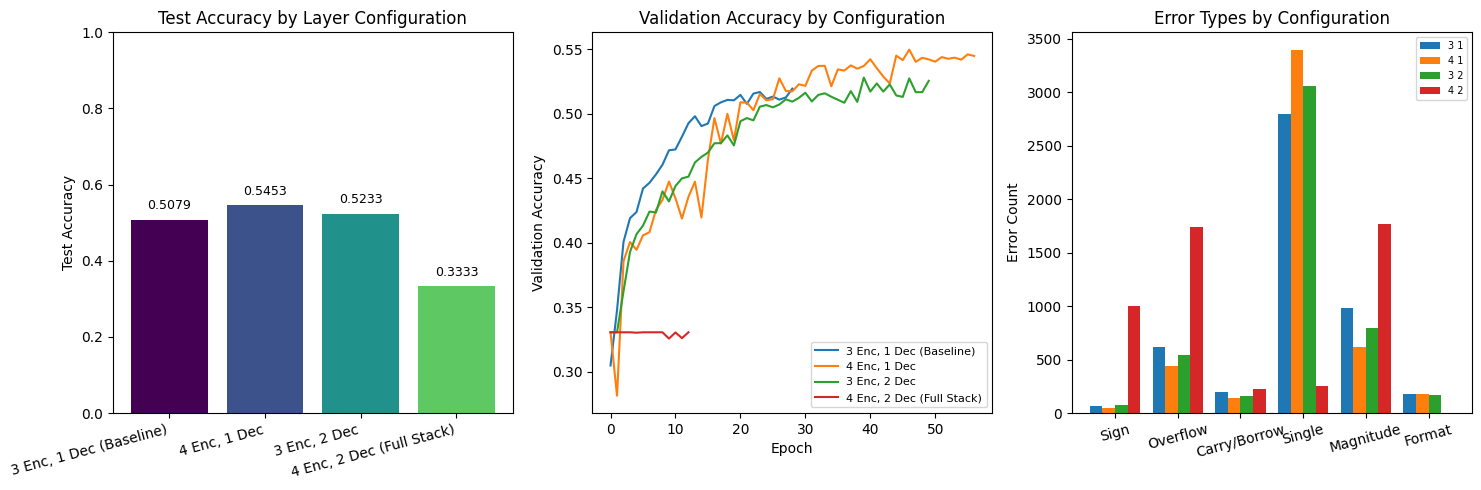

Image-to-Text: Stacked LSTM Configuration Summary
Configuration | Accuracy | Parameters | Carry Errors
3 Enc, 1 Dec (Baseline) | 0.5079 | 3,280,269 | 198
4 Enc, 1 Dec | 0.5453 | 8,426,893 | 137
3 Enc, 2 Dec | 0.5233 | 3,475,725 | 162
4 Enc, 2 Dec (Full Stack) | 0.3333 | 8,622,349 | 221
Carry Error Analysis:
Baseline carry errors: 198
Best configuration (4 Enc, 1 Dec): 137
Carry error reduction: 30.8%
Best Configuration: 4 Enc, 1 Dec
Best Accuracy: 0.5453
Improvement over Baseline: +0.0374 (+7.36%)


In [17]:
# stacking LSTM for image-to-text model with comparison
def build_configurable_img2text_model(encoder_conv_layers=3, decoder_lstm_layers=1):
    """building image-to-text model with configurable ConvLSTM2D depth"""
    model = tf.keras.Sequential()

    # using ConvLSTM2D feature extractor for spatiotemporal encoding
    if encoder_conv_layers == 3:
        # using baseline: 3 ConvLSTM2D layers (same as build_img2text_model)
        model.add(ConvLSTM2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding="same",
                            return_sequences=True, input_shape=(5, 28, 28, 1), dropout=0.3))
        model.add(BatchNormalization())
        model.add(TimeDistributed(MaxPooling2D((2, 2))))
        
        model.add(ConvLSTM2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding="same",
                            return_sequences=True, dropout=0.3))
        model.add(BatchNormalization())
        model.add(TimeDistributed(MaxPooling2D((2, 2))))
        
        model.add(ConvLSTM2D(filters=128, kernel_size=(3, 3), padding="same",
                            return_sequences=False, dropout=0.3))
        model.add(BatchNormalization())
    else:
        # using stacked encoder: 4 ConvLSTM2D layers for deeper feature extraction
        model.add(ConvLSTM2D(filters=32, kernel_size=(3, 3), strides=(1, 1), padding="same",
                            return_sequences=True, input_shape=(5, 28, 28, 1), dropout=0.3))
        model.add(BatchNormalization())
        model.add(TimeDistributed(MaxPooling2D((2, 2))))
        
        model.add(ConvLSTM2D(filters=64, kernel_size=(3, 3), strides=(1, 1), padding="same",
                            return_sequences=True, dropout=0.3))
        model.add(BatchNormalization())
        model.add(TimeDistributed(MaxPooling2D((2, 2))))
        
        model.add(ConvLSTM2D(filters=128, kernel_size=(3, 3), padding="same",
                            return_sequences=True, dropout=0.3))
        model.add(BatchNormalization())
        
        model.add(ConvLSTM2D(filters=256, kernel_size=(3, 3), padding="same",
                            return_sequences=False, dropout=0.3))
        model.add(BatchNormalization())

    # flattening and projecting to latent space
    model.add(Flatten())
    model.add(Dense(256, activation="relu"))
    model.add(Dropout(0.5))

    model.add(RepeatVector(max_answer_length))

    # configuring decoder LSTM layers
    if decoder_lstm_layers == 1:
        model.add(LSTM(256, return_sequences=True))
    else:
        # using stacked decoder for more complex sequence generation
        model.add(LSTM(256, return_sequences=True))
        model.add(LSTM(128, return_sequences=True))

    model.add(TimeDistributed(Dense(len(unique_characters), activation="softmax")))
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    model.summary()

    return model

print("Image-to-Text: Stacked LSTM Configuration Comparison")

# splitting the data
X_img_expanded = np.expand_dims(X_img, axis=-1)
X_img_train, X_img_val, X_img_test, y_txt_train, y_txt_val, y_txt_test, _, test_idx = split_data_with_val(
    X_img_expanded, y_text_onehot, train_size=0.75
)

img_configurations = [
    ("3 Enc, 1 Dec (Baseline)", 3, 1),
    ("4 Enc, 1 Dec", 4, 1),
    ("3 Enc, 2 Dec", 3, 2),
    ("4 Enc, 2 Dec (Full Stack)", 4, 2),
]

img_stacked_results = {}
img_stacked_error_counts = {}

# getting raw text for error analysis (reusing test_idx from the split above)
X_img_test_raw = X_text[test_idx]

for name, enc, dec in img_configurations:
    print(f"Configuration: {name}")

    model = build_configurable_img2text_model(enc, dec)
    total_params = model.count_params()
    print(f"Total parameters: {total_params:,}")

    history, acc = train_evaluate_model(
        model, X_img_train, y_txt_train, X_img_val, y_txt_val, X_img_test, y_txt_test,
        batch_size=64, verbose=1
    )
    print(f"Test Accuracy: {acc:.4f}")

    img_stacked_results[name] = {
        "accuracy": acc,
        "history": history.history,
        "params": total_params,
        "enc_layers": enc,
        "dec_layers": dec,
        "model": model
    }

    # collecting error analysis
    error_counts, _, _ = analyze_errors(model, X_img_test, y_txt_test, X_img_test_raw)
    img_stacked_error_counts[name] = error_counts
    print(f"Error breakdown: {error_counts}")

# visualizing the results
plt.figure(figsize=(15, 5))

# visualizing test accuracy
plt.subplot(1, 3, 1)
names = list(img_stacked_results.keys())
accs = [img_stacked_results[n]["accuracy"] for n in names]
bars = plt.bar(range(len(names)), accs, color=[viridis(i/len(names)) for i in range(len(names))])
plt.xticks(range(len(names)), names, rotation=15, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy by Layer Configuration")
plt.ylim(0, 1.0)
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x() + bar.get_width() / 2, acc + 0.02, f"{acc:.4f}",
             ha="center", va="bottom", fontsize=9)

# visualizing validation accuracy
plt.subplot(1, 3, 2)
for name, data in img_stacked_results.items():
    plt.plot(data["history"]["val_accuracy"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Configuration")
plt.legend(fontsize=8)

# visualizing error types by configuration
plt.subplot(1, 3, 3)
error_types = list(img_stacked_error_counts[names[0]].keys())
x = np.arange(len(error_types))
width = 0.2
for i, (name, errors) in enumerate(img_stacked_error_counts.items()):
    counts = list(errors.values())
    plt.bar(x + i * width, counts, width, label=name.split()[0] + " " + name.split()[2])
plt.xticks(x + 1.5 * width, [e.split()[0] for e in error_types], rotation=15)
plt.ylabel("Error Count")
plt.title("Error Types by Configuration")
plt.legend(fontsize=7)

plt.tight_layout()
plt.savefig("i2t_stacked_results.png")
plt.show()

# printing the summary table with carry errors
print("Image-to-Text: Stacked LSTM Configuration Summary")
print("Configuration | Accuracy | Parameters | Carry Errors")
baseline_acc = img_stacked_results["3 Enc, 1 Dec (Baseline)"]["accuracy"]
for name, data in img_stacked_results.items():
    acc = data["accuracy"]
    params = data["params"]
    carry_errs = img_stacked_error_counts[name]["Carry/Borrow Error"]
    improvement = acc - baseline_acc
    print(f"{name} | {acc:.4f} | {params:,} | {carry_errs}")

# analyzing the carry error reduction
print("Carry Error Analysis:")
baseline_carry = img_stacked_error_counts["3 Enc, 1 Dec (Baseline)"]["Carry/Borrow Error"]
best_config = min(img_stacked_error_counts.keys(), key=lambda k: img_stacked_error_counts[k]["Carry/Borrow Error"])
best_carry = img_stacked_error_counts[best_config]["Carry/Borrow Error"]
if baseline_carry > 0:
    reduction_pct = (baseline_carry - best_carry) / baseline_carry * 100
    print(f"Baseline carry errors: {baseline_carry}")
    print(f"Best configuration ({best_config}): {best_carry}")
    print(f"Carry error reduction: {reduction_pct:.1f}%")
else:
    print("No carry errors in baseline")

best_config = max(img_stacked_results.keys(), key=lambda k: img_stacked_results[k]["accuracy"])
best_acc = img_stacked_results[best_config]["accuracy"]
print(f"Best Configuration: {best_config}")
print(f"Best Accuracy: {best_acc:.4f}")
print(f"Improvement over Baseline: {best_acc - baseline_acc:+.4f} ({(best_acc - baseline_acc) / baseline_acc * 100:+.2f}%)")

In [18]:
# assessing carry error reduction
print("Image-to-Text: Stacked LSTM Carry Error Comparison")
carry_key = "Carry/Borrow Error"
baseline_key = "3 Enc, 1 Dec (Baseline)"
enc4_key = "4 Enc, 1 Dec"
full_key = "4 Enc, 2 Dec (Full Stack)"
print(f"Baseline (3+1) Carry Errors: {img_stacked_error_counts[baseline_key][carry_key]}")
print(f"4 Enc, 1 Dec Carry Errors: {img_stacked_error_counts[enc4_key][carry_key]}")
print(f"4 Enc, 2 Dec Carry Errors: {img_stacked_error_counts[full_key][carry_key]}")

# computing the percentage improvement
baseline_carry = img_stacked_error_counts[baseline_key][carry_key]
stacked_4enc_carry = img_stacked_error_counts[enc4_key][carry_key]

if baseline_carry > 0:
    improvement_pct = (baseline_carry - stacked_4enc_carry) / baseline_carry * 100
    print(f"Adding encoder layer reduces carry errors by {improvement_pct:.1f}%")

Image-to-Text: Stacked LSTM Carry Error Comparison
Baseline (3+1) Carry Errors: 198
4 Enc, 1 Dec Carry Errors: 137
4 Enc, 2 Dec Carry Errors: 221
Adding encoder layer reduces carry errors by 30.8%
